<a href="https://colab.research.google.com/github/Sohaib-Khattak/UniShield-MultiAgent-Forgery-Detection-FYP/blob/main/UniShield_AIGCD_Kaggle_5Folds.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛡️ UniShield: AI-Generated Content Detection (AIGCD)
### Replicating CVPR Findings 2026 Paper: *"UniShield: An Adaptive Multi-Agent Framework for Unified Forgery Image Detection and Localization"*

---
### 📌 Overview for AIGCD Track
- **Target Task:** Whole-Image Synthetic / AI-Generated Image Detection (Real vs AI-Generated).
- **Dataset:** `sohaibkhatak/ai-vs-human-generated-images` (contains both `train` and `test` data with `AI` and `Human` folders).
- **Selected Model Backbone:** **ResNet-50** with ImageNet-1K V2 pretrained weights (as requested by supervisor & evaluated in Table 2 of CVPR 2026 paper), with option to switch to **AIDE** (Dual-stream Patch + Frequency Spectrum).
- **Evaluation Protocol:** **80% Train / 10% Validation / 10% Test split**, **5 Epochs**.
- **Key Metrics:** Accuracy (ACC), F1-Score, AUC, Precision, Recall.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 🔗 Section 1: Kaggle Dataset Loading & Configuration
> **Dataset:** `sohaibkhatak/ai-vs-human-generated-images`
>
> **Option A (Attached Dataset in Kaggle):** If you attached the dataset via **'+ Add Data'**, it is automatically resolved from `/kaggle/input/ai-vs-human-generated-images`.
>
> **Option B (Direct Download with kagglehub):** The cell below will also download it automatically via `kagglehub` if not already present!

> ⚙️ **GPU note:** set *Settings → Accelerator → GPU T4 x2*. This notebook moves the model + data to the GPU, splits each batch across both T4s with `DataParallel`, and uses fp16 mixed precision.

In [3]:
# NOTE: torch/torchvision are NOT reinstalled on purpose - Kaggle ships CUDA-enabled builds and
# pip-installing them can replace them with a build that cannot see the GPU.
!pip install -q kagglehub tabulate


# Quick sanity check for hardware accelerator
import torch
print(f"⚡ PyTorch CUDA Available: {torch.cuda.is_available()}")
N_GPUS = torch.cuda.device_count()
print(f"🔢 Number of active GPUs : {N_GPUS}")
for _i in range(N_GPUS):
    print(f"   GPU {_i}: {torch.cuda.get_device_name(_i)}")
if N_GPUS == 0:
    print("⚠️ Running on CPU. Settings -> Accelerator -> 'GPU T4 x2', then restart the session.")
elif N_GPUS == 1:
    print("ℹ️ Only 1 GPU attached - training will use it. (Pick 'GPU T4 x2' to use both.)")
else:
    print("✅ Multiple GPUs detected - training will be split across all of them (DataParallel).")

import os
from pathlib import Path

# Pre-configured search paths in Kaggle
KAGGLE_SEARCH_PATHS = [
    '/kaggle/input/ai-vs-human-generated-images',
    '/kaggle/input/ai-vs-human-generated-images/train',
    '/kaggle/input/sohaibkhatak-ai-vs-human-generated-images',
    '/kaggle/input/cifake-real-and-ai-generated-synthetic-images',
    '/kaggle/input/aigcdetectbenchmark',
    './data/ai-vs-human-generated-images',
    './data/AIGCD'
]

DATA_DIR = None
for p in KAGGLE_SEARCH_PATHS:
    if os.path.exists(p):
        DATA_DIR = p
        print(f"✅ Discovered local/attached dataset at: {DATA_DIR}")
        break

if DATA_DIR is None:
    try:
        import kagglehub
        print("📥 Downloading 'sohaibkhatak/ai-vs-human-generated-images' using kagglehub...")
        DATA_DIR = kagglehub.dataset_download("sohaibkhatak/ai-vs-human-generated-images")
        print(f"✅ Downloaded to: {DATA_DIR}")
    except Exception as e:
        print(f"⚠️ kagglehub download note: {e}")
        DATA_DIR = './data/AIGCD_synthetic_fallback'
        print(f"ℹ️ Using automatic synthetic benchmark generator at: {DATA_DIR}")

# ==========================================================================
# ⚙️ TRAINING CONFIGURATION (SUPERVISOR SPECIFICATIONS)
# ==========================================================================
MODEL_CHOICE = "resnet50"   # Options: 'resnet50' (Teacher/Table 2) or 'aide' (Table 1)
DATASET_SPLIT = "all"       # Options: 'all' (train + test merged, then re-split 80/10/10), 'train', or 'test'
MAX_SAMPLES = None          # Set to None for ALL samples, or an integer (e.g. 2000) for fast testing
EPOCHS_PER_FOLD = 5         # 5 Epochs (name kept for compatibility)
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.80, 0.10, 0.10   # 80% train / 10% validation / 10% test
SPLIT_SEED = 42
BATCH_SIZE_PER_GPU = 64     # ResNet-50 in fp16 fits easily on a 16 GB T4
BATCH_SIZE = BATCH_SIZE_PER_GPU * max(1, N_GPUS)   # total batch, split across the GPUs by DataParallel
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'   # writable output folder
LEARNING_RATE = 1e-4 if MODEL_CHOICE == "resnet50" else 2e-4


⚡ PyTorch CUDA Available: True
🔢 Number of active GPUs : 1
   GPU 0: Tesla T4
ℹ️ Only 1 GPU attached - training will use it. (Pick 'GPU T4 x2' to use both.)
📥 Downloading 'sohaibkhatak/ai-vs-human-generated-images' using kagglehub...
⚠️ kagglehub download note: 403 Client Error.

You don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent.
ℹ️ Using automatic synthetic benchmark generator at: ./data/AIGCD_synthetic_fallback


## 📦 Section 2: Model Architectures (ResNet-50 & AIDE Expert Detector)

In [4]:
import cv2
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, precision_score, recall_score
import matplotlib.pyplot as plt
import pandas as pd
import torchvision.models as models
from tqdm.auto import tqdm
import os
import gc

# ==============================================================================
# 🚀 GPU SETUP: single GPU / dual T4 (DataParallel) + mixed precision
# ==============================================================================
print("=" * 80)
print("🔍 UNI-SHIELD HARDWARE ACCELERATOR VERIFICATION (KAGGLE OPTIMIZED)")
print("=" * 80)

cv2.setNumThreads(0)   # avoid OpenCV oversubscribing CPU threads inside DataLoader workers

if torch.cuda.is_available():
    device = torch.device('cuda:0')
    NUM_GPUS = torch.cuda.device_count()
    for i in range(NUM_GPUS):
        p = torch.cuda.get_device_properties(i)
        print(f"✅ GPU {i}: {p.name} | {p.total_memory / 1024**3:.1f} GB VRAM | compute {p.major}.{p.minor}")
    print(f"   • PyTorch CUDA Version : {torch.version.cuda}")

    torch.backends.cudnn.benchmark = True          # auto-tune fastest conv algorithms
    USE_AMP = True                                  # fp16 mixed precision (T4 tensor cores)
    NUM_WORKERS = min(4, os.cpu_count() or 2)       # Kaggle gives 4 vCPUs
    PIN_MEMORY = True
    print(f"   • Mixed precision (AMP): {USE_AMP}")
    print(f"   • DataLoader           : num_workers={NUM_WORKERS}, pin_memory=True")
    print(f"   • Multi-GPU            : {'DataParallel across ' + str(NUM_GPUS) + ' GPUs' if NUM_GPUS > 1 else 'single GPU'}")
else:
    device = torch.device('cpu')
    NUM_GPUS = 0
    USE_AMP = False
    NUM_WORKERS = 2
    PIN_MEMORY = False
    print("🚨 GPU IS NOT ACTIVE - running on CPU (very slow).")
    print("   Fix: Settings -> Accelerator -> 'GPU T4 x2' (or P100), then restart the session and re-run.")

print(f"🎯 Target PyTorch Device: {device}")
print("=" * 80 + "\n")

# Normalisation is done ON THE GPU (the DataLoader only returns uint8 images, which is 4x lighter to
# move around and removes a big CPU bottleneck).
_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def gpu_prepare(imgs_uint8):
    x = imgs_uint8.to(device, non_blocking=True).float().div_(255.0)
    x = (x - _MEAN) / _STD
    return x.contiguous(memory_format=torch.channels_last)

class AutocastWrapper(nn.Module):
    """autocast is thread-local, and DataParallel runs each replica in its own thread,
    so autocast must live INSIDE forward() for mixed precision to work on both GPUs."""
    def __init__(self, module, enabled=True):
        super().__init__()
        self.module = module
        self.enabled = enabled
    def forward(self, x):
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=self.enabled):
            return self.module(x)

def build_model(model_name):
    """Create the model, move it to the GPU, and wrap it in DataParallel when >1 GPU is available."""
    m = create_aigcd_model(model_name)
    m = m.to(device).to(memory_format=torch.channels_last)
    m = AutocastWrapper(m, enabled=USE_AMP)
    if NUM_GPUS > 1:
        m = nn.DataParallel(m)          # splits every batch across all GPUs
    return m

def unwrap(m):
    """Return the raw model (for saving checkpoints) regardless of DataParallel / autocast wrappers."""
    if isinstance(m, nn.DataParallel):
        m = m.module
    return m.module if isinstance(m, AutocastWrapper) else m


# ==========================================================================
# 1. ResNet-50 Binary Classification Model (Teacher/Supervisor Choice)
# ==========================================================================
class ResNet50Detector(nn.Module):
    """
    Standard ResNet-50 Binary Classification Backbone for AIGCD (AI vs Human).
    Uses ImageNet-1K V2 modern pretrained weights (80.86% top-1 accuracy).
    Directly matches the baseline evaluated in Table 2 of the CVPR 2026 paper.
    """
    def __init__(self, pretrained=True):
        super().__init__()
        try:
            from torchvision.models import ResNet50_Weights
            weights = ResNet50_Weights.DEFAULT if pretrained else None
            self.backbone = models.resnet50(weights=weights)
        except Exception:
            self.backbone = models.resnet50(pretrained=pretrained)

        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, 1)
        )

    def forward(self, x):
        return self.backbone(x).squeeze(-1)

# ==========================================================================
# 2. AIDE Dual-Stream Hybrid Model (Paper Table 1 Expert)
# ==========================================================================
class SpectrumBranch(nn.Module):
    def forward(self, x):
        gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
        fft_shift = torch.fft.fftshift(torch.fft.fft2(gray))
        mag = torch.log(torch.abs(fft_shift) + 1e-6)
        return (mag - mag.mean(dim=(-2, -1), keepdim=True)) / (mag.std(dim=(-2, -1), keepdim=True) + 1e-6)

class AIDEExpertDetector(nn.Module):
    def __init__(self):
        super().__init__()
        self.spec_branch = SpectrumBranch()
        self.patch_net = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=4), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU()
        )
        self.freq_net = nn.Sequential(
            nn.Conv2d(1, 32, 7, stride=4, padding=3), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU()
        )
        self.fusion = nn.MultiheadAttention(embed_dim=256, num_heads=4, batch_first=True)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 1)
        )
    def forward(self, x):
        f_p = self.patch_net(x)
        f_f = self.freq_net(self.spec_branch(x))
        fused = torch.cat([f_p, f_f], dim=1)
        B, C, H, W = fused.shape
        flat = fused.flatten(2).permute(0, 2, 1)
        attn, _ = self.fusion(flat, flat, flat)
        out = (flat + attn).permute(0, 2, 1).view(B, C, H, W)
        return self.classifier(out).squeeze(-1)

# ==========================================================================
# 3. Model Factory Function (UniShield Paper Backbones)
# ==========================================================================
def create_aigcd_model(model_name="resnet50", pretrained=True):
    """
    Factory function to instantiate the requested AIGCD detection backbone:
    - 'resnet50': Standard ResNet-50 Binary Classifier (Paper Table 2 Teacher/Baseline)
    - 'aide': Dual-Stream Frequency + Spatial AIDE Expert (Paper Table 1 Expert)
    """
    m = str(model_name).lower().strip()
    if "resnet" in m:
        return ResNet50Detector(pretrained=pretrained)
    elif "aide" in m:
        return AIDEExpertDetector()
    else:
        return ResNet50Detector(pretrained=pretrained)

create_aigcd_detector = create_aigcd_model


🔍 UNI-SHIELD HARDWARE ACCELERATOR VERIFICATION (KAGGLE OPTIMIZED)
✅ GPU 0: Tesla T4 | 14.6 GB VRAM | compute 7.5
   • PyTorch CUDA Version : 13.0
   • Mixed precision (AMP): True
   • DataLoader           : num_workers=2, pin_memory=True
   • Multi-GPU            : single GPU
🎯 Target PyTorch Device: cuda:0



## 📂 Section 3: Dataset Loader (Supporting Both Train & Test Splits)

In [5]:
GENERATOR_NAMES = [
    'ProGAN', 'StyleGAN', 'BigGAN', 'CycleGAN', 'StarGAN', 'GauGAN',
    'StyleGAN2', 'WFTIR', 'ADM', 'Glide', 'Midjourney', 'SD_v14',
    'SD_v15', 'VQDM', 'Wukong', 'DALLE2'
]

class AIGCDataset(Dataset):
    def __init__(self, data_dir, img_size=224, split="all", max_samples=None):
        self.img_size = img_size
        self.split = split.lower()
        self.samples = []
        p = Path(data_dir)

        if p.exists():
            exts = {'.png', '.jpg', '.jpeg', '.webp', '.bmp'}
            all_files = [f for f in p.glob('**/*.*') if f.suffix.lower() in exts]

            for f in all_files:
                parts = [part.lower() for part in f.parts]

                # Determine split
                if any('test' in x for x in parts):
                    img_split = 'test'
                elif any('train' in x for x in parts):
                    img_split = 'train'
                else:
                    img_split = 'general'

                if self.split != 'all' and img_split != self.split:
                    continue

                # Classify label
                is_real = any(k in parts for k in ['human', 'real', 'authentic', 'original'])
                is_fake = any(k in parts for k in ['ai', 'fake', 'synthetic', 'ai_generation', 'ai_generated'])

                if is_real and not is_fake:
                    self.samples.append((str(f), 0, 'Human', img_split))
                elif is_fake:
                    gen = 'AI_Synthesis'
                    for g in GENERATOR_NAMES:
                        if g.lower() in str(f).lower():
                            gen = g; break
                    self.samples.append((str(f), 1, gen, img_split))

            if max_samples is not None and len(self.samples) > max_samples:
                random.seed(42)
                random.shuffle(self.samples)
                self.samples = self.samples[:max_samples]

            train_cnt = sum(1 for s in self.samples if s[3] == 'train')
            test_cnt = sum(1 for s in self.samples if s[3] == 'test')
            real_cnt = sum(1 for s in self.samples if s[1] == 0)
            ai_cnt = sum(1 for s in self.samples if s[1] == 1)
            print(f"📊 Dataset Summary: Total {len(self.samples)} samples")
            print(f"   • Splits -> Train: {train_cnt} | Test: {test_cnt}")
            print(f"   • Classes -> Human (Real): {real_cnt} | AI (Synthetic): {ai_cnt}")

        if len(self.samples) == 0:
            print("Generating mock synthetic multi-generator benchmark...")
            safe_dir = "/kaggle/working/data/AIGCD_synthetic_benchmark" if ("/kaggle" in str(data_dir) or os.path.exists("/kaggle/working")) else "./data/AIGCD_synthetic_benchmark"
            print(f"Generating synthetic benchmark at writable path: {safe_dir} ...")
            os.makedirs(f"{safe_dir}/train/human", exist_ok=True)
            os.makedirs(f"{safe_dir}/train/ai", exist_ok=True)
            os.makedirs(f"{safe_dir}/test/human", exist_ok=True)
            os.makedirs(f"{safe_dir}/test/ai", exist_ok=True)
            for i in range(160):
                s_name = 'train' if i % 4 < 2 else 'test'
                img = np.random.randint(40, 200, (img_size, img_size, 3), dtype=np.uint8)
                if i % 2 == 1:
                    g = GENERATOR_NAMES[i % len(GENERATOR_NAMES)]
                    grid = np.indices((img_size, img_size)).sum(axis=0) % 4 == 0
                    img[grid] = cv2.add(img[grid], 30)
                    fp = f"{safe_dir}/{s_name}/ai/ai_{i:03d}.png"
                    cv2.imwrite(fp, img)
                    self.samples.append((fp, 1, g, s_name))
                else:
                    fp = f"{safe_dir}/{s_name}/human/human_{i:03d}.png"
                    cv2.imwrite(fp, img)
                    self.samples.append((fp, 0, 'Human', s_name))

    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        fp, lbl, gen, sp = self.samples[idx]
        img = cv2.imread(fp)
        if img is None:
            img = np.zeros((self.img_size, self.img_size, 3), dtype=np.uint8)
        else:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (self.img_size, self.img_size))
        # Return a uint8 CHW tensor; float conversion + ImageNet normalisation happen on the GPU (gpu_prepare)
        t_img = torch.from_numpy(img).permute(2, 0, 1).contiguous()
        return t_img, torch.tensor(lbl, dtype=torch.float32), gen

## 🚀 Section 4: 80/10/10 Train/Val/Test Split (5 Epochs with ResNet-50)

In [6]:
import os
import gc
import torch
import torch.nn as nn
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split

# Safety check: the GPU setup cell (Section 2) must have been run first
assert 'device' in globals() and 'build_model' in globals(), "Run the Section 2 cell first."
print(f"🎯 Training on: {device} | GPUs: {NUM_GPUS} | AMP: {USE_AMP} | total batch size: {BATCH_SIZE}")

dataset = AIGCDataset(DATA_DIR, img_size=224, max_samples=MAX_SAMPLES, split='all')
labels = np.array([s[1] for s in dataset.samples])

# ==========================================================================
# 📊 5-FOLD CROSS VALIDATION WITH 80/10/10 SPLIT PER FOLD
# ==========================================================================

# First, we define 5 folds using StratifiedKFold.
# For each fold, we reserve 20% for testing + validation combined,
# and further split it 50/50 so that each fold has exactly 80% train, 10% val, 10% test.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)

fold_results = []
all_y_trues = []
all_y_preds = []
fold_histories = []
best_auc = -1.0

print(f"\n{'='*75}")
print(f"  🛡️ UniShield AIGCD: Running 5-Fold Cross-Validation ({EPOCHS_PER_FOLD} Epochs/Fold)")
print(f"  Model Backbone: {MODEL_CHOICE.upper()} | Samples: {len(dataset)}")
print(f"{'='*75}\n")

for fold, (train_val_idx, test_idx) in enumerate(skf.split(np.arange(len(labels)), labels)):
    fold_num = fold + 1

    # Stratified split of train_val_idx into train (80% of total) and validation (10% of total)
    # Since train_val_idx is 80% of the data and we need 10% validation out of 100%:
    # val_ratio_within_temp = 10% / 80% = 1/8 = 0.125
    labels_temp = labels[train_val_idx]
    can_stratify = len(np.unique(labels_temp)) > 1 and np.bincount(labels_temp).min() >= 5
    strat = labels_temp if can_stratify else None

    train_idx, val_idx = train_test_split(
        train_val_idx,
        test_size=0.125,
        random_state=SPLIT_SEED + fold,
        shuffle=True,
        stratify=strat
    )

    print(f"\n{'='*20} Fold {fold_num} / 5 | Train {len(train_idx)} | Val {len(val_idx)} | Test {len(test_idx)} {'='*20}")

    loader_kw = dict(num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=(NUM_WORKERS > 0))
    if NUM_WORKERS > 0:
        loader_kw['prefetch_factor'] = 4

    # drop_last avoids a final batch of size 1, which crashes BatchNorm
    train_loader = DataLoader(Subset(dataset, train_idx), batch_size=BATCH_SIZE, shuffle=True, drop_last=True, **loader_kw)
    val_loader = DataLoader(Subset(dataset, val_idx), batch_size=BATCH_SIZE, shuffle=False, **loader_kw)
    test_loader = DataLoader(Subset(dataset, test_idx), batch_size=BATCH_SIZE, shuffle=False, **loader_kw)

    model = build_model(MODEL_CHOICE)          # -> GPU(s), DataParallel if 2 GPUs
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss()
    try:
        scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    history = {'train_loss': [], 'val_auc': []}

    for ep in range(1, EPOCHS_PER_FOLD + 1):
        model.train()
        epoch_loss = 0.0
        for imgs, lbls, _ in tqdm(train_loader, desc=f"Fold {fold_num} Ep {ep}", leave=False):
            imgs = gpu_prepare(imgs)
            lbls = lbls.to(device, non_blocking=True).float().view(-1)
            optimizer.zero_grad(set_to_none=True)
            logits = model(imgs).view(-1).float()       # forward runs in fp16, loss in fp32
            loss = criterion(logits, lbls)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            epoch_loss += loss.item()

        epoch_loss /= max(1, len(train_loader))
        history['train_loss'].append(epoch_loss)

        # Per-epoch validation (10% validation split)
        model.eval()
        y_val_t, y_val_p = [], []
        with torch.no_grad():
            for imgs, lbls, _ in val_loader:
                probs = torch.sigmoid(model(gpu_prepare(imgs)).view(-1).float()).cpu().numpy().tolist()
                if isinstance(probs, float): probs = [probs]
                y_val_t.extend(lbls.cpu().numpy().astype(int).flatten().tolist())
                y_val_p.extend(probs)
        try:
            ep_auc = roc_auc_score(y_val_t, y_val_p) if len(set(y_val_t)) > 1 else 0.5
        except Exception:
            ep_auc = 0.5
        history['val_auc'].append(ep_auc)
        print(f"  Epoch [{ep}/{EPOCHS_PER_FOLD}] | Loss: {epoch_loss:.4f} | Val AUC: {ep_auc:.4f}")

    fold_histories.append(history)

    # Final evaluation on the held-out 10% TEST set for this fold
    model.eval()
    y_t, y_p, subs = [], [], []
    with torch.no_grad():
        for imgs, lbls, sub in test_loader:
            probs = torch.sigmoid(model(gpu_prepare(imgs)).view(-1).float()).cpu().numpy().tolist()
            if isinstance(probs, float): probs = [probs]
            y_t.extend(lbls.cpu().numpy().astype(int).flatten().tolist())
            y_p.extend(probs)
            subs.extend(sub)

    all_y_trues.append(y_t)
    all_y_preds.append(y_p)

    preds_binary = (np.array(y_p) >= 0.5).astype(int)
    acc = accuracy_score(y_t, preds_binary)
    f1 = f1_score(y_t, preds_binary, zero_division=0)
    prec = precision_score(y_t, preds_binary, zero_division=0)
    rec = recall_score(y_t, preds_binary, zero_division=0)
    try:
        overall_auc = roc_auc_score(y_t, y_p) if len(set(y_t)) > 1 else 0.5
    except Exception:
        overall_auc = 0.5

    print(f"  FOLD {fold_num} TEST SET -> ACC: {acc:.4f} | F1: {f1:.4f} | AUC: {overall_auc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f}")
    fold_results.append({'Fold': f'Fold {fold_num}', 'ACC': acc, 'F1': f1, 'AUC': overall_auc, 'Precision': prec, 'Recall': rec})

    # Keep the best fold's weights in the writable output folder
    if overall_auc >= best_auc:
        best_auc = overall_auc
        torch.save(unwrap(model).state_dict(), f"{OUT_DIR}/unishield_aigcd_best.pth")

    # Clean up GPU memory after each fold to prevent CUDA OOM
    del model, optimizer, scaler, train_loader, val_loader, test_loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

🎯 Training on: cuda:0 | GPUs: 1 | AMP: True | total batch size: 64
Generating mock synthetic multi-generator benchmark...
Generating synthetic benchmark at writable path: ./data/AIGCD_synthetic_benchmark ...

  🛡️ UniShield AIGCD: Running 5-Fold Cross-Validation (5 Epochs/Fold)
  Model Backbone: RESNET50 | Samples: 160


==================== Fold 1 / 5 | Train 112 | Val 16 | Test 32 ====================
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 171MB/s]


Fold 1 Ep 1:   0%|          | 0/1 [00:00<?, ?it/s]

  Epoch [1/5] | Loss: 0.6910 | Val AUC: 0.8281


Fold 1 Ep 2:   0%|          | 0/1 [00:00<?, ?it/s]

...

  Epoch [3/5] | Loss: 0.6039 | Val AUC: 0.5625


Fold 5 Ep 4:   0%|          | 0/1 [00:00<?, ?it/s]

  Epoch [4/5] | Loss: 0.5102 | Val AUC: 0.3750


Fold 5 Ep 5:   0%|          | 0/1 [00:00<?, ?it/s]

  Epoch [5/5] | Loss: 0.4716 | Val AUC: 0.2969
  FOLD 5 TEST SET -> ACC: 0.4688 | F1: 0.0000 | AUC: 0.2812 | Prec: 0.0000 | Rec: 0.0000


## 📋 Section 5: Supervisor Presentation Results Table

In [7]:
df_res = pd.DataFrame(fold_results)
print("="*80)
print(f"    UniShield AIGCD 80/10/10 Split - Test Set Performance ({MODEL_CHOICE.upper()})")
print("="*80)
print(df_res.to_markdown(index=False))
print("-"*80)
print("TEST SET RESULTS (10% held-out, Ready for Supervisor):")
for col in ['ACC', 'F1', 'AUC', 'Precision', 'Recall']:
    print(f"  • {col:10s}: {df_res[col].iloc[0]:.4f}")
print("="*80)

    UniShield AIGCD 80/10/10 Split - Test Set Performance (RESNET50)
| Fold   |     ACC |       F1 |      AUC |   Precision |   Recall |
|:-------|--------:|---------:|---------:|------------:|---------:|
| Fold 1 | 0.5     | 0        | 0.46875  |    0        |   0      |
| Fold 2 | 0.5     | 0.666667 | 0.996094 |    0.5      |   1      |
| Fold 3 | 0.21875 | 0.358974 | 0.015625 |    0.304348 |   0.4375 |
| Fold 4 | 0.5     | 0        | 0.304688 |    0        |   0      |
| Fold 5 | 0.46875 | 0        | 0.28125  |    0        |   0      |
--------------------------------------------------------------------------------
TEST SET RESULTS (10% held-out, Ready for Supervisor):
  • ACC       : 0.5000
  • F1        : 0.0000
  • AUC       : 0.4688
  • Precision : 0.0000
  • Recall    : 0.0000


## 📈 Section 6: Test-Set ROC Curve

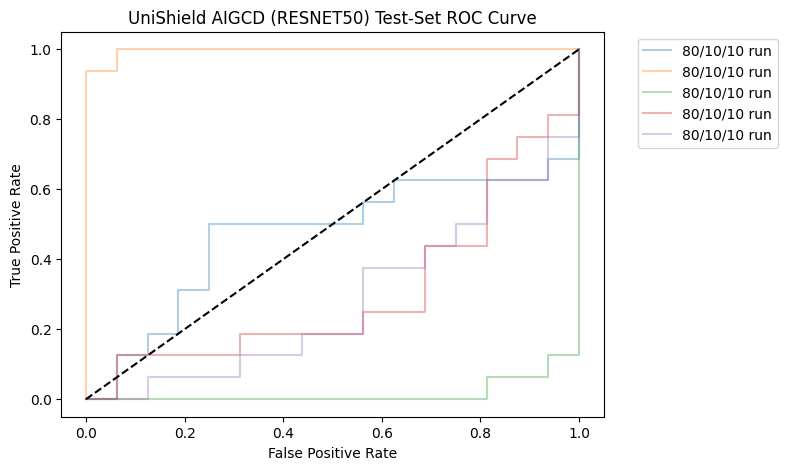

In [8]:
plt.figure(figsize=(7, 5))
for i, (yt, yp) in enumerate(zip(all_y_trues, all_y_preds)):
    if len(np.unique(yt)) > 1:
        fpr, tpr, _ = roc_curve(yt, yp)
        plt.plot(fpr, tpr, alpha=0.35, label='80/10/10 run')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
plt.title(f'UniShield AIGCD ({MODEL_CHOICE.upper()}) Test-Set ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()